# The camera and the dataset

This notebook puts the forward model of the chapter to work on SPEED+. It reads the camera and the labels, measures how much the lens bends the image, checks the convention of the poses against the images, and describes the dataset from the point of view of pose estimation.

The images of SPEED+ are distributed under a non-commercial license and are not reproduced here: the notebook reads them to compute numbers, and draws only what follows from the labels and the geometry. The files are fetched from the public archive the first time they are needed, into the local folder `data/speedplus`.

In [1]:
%matplotlib inline

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_A = "#1f77b4"
COL_B = "#d62728"
COL_C = "#9467bd"
COL_D = "#2ca02c"

# local copy of the dataset, filled on demand from the public archive
DATA = Path("../../data/speedplus")

from matplotlib.path import Path as Polygon
from scipy.spatial import ConvexHull

from ios_pose_estimation.camera import project_pose
from ios_pose_estimation.rotations import quaternion_conjugate
from ios_pose_estimation.speedplus import TANGO_EDGES, TANGO_KEYPOINTS, SpeedPlus

dataset = SpeedPlus(DATA)
camera = dataset.camera()

## The camera

`camera.json` gives the intrinsic matrix and the five distortion coefficients of the lens, in the order used by OpenCV, $(k_1, k_2, p_1, p_2, k_3)$.

In [2]:
print(f"image: {camera.width} x {camera.height} px")
print(f"focal length: fx = {camera.fx:.1f} px, fy = {camera.fy:.1f} px; principal point ({camera.cx:.0f}, {camera.cy:.0f})")
print(f"field of view: {np.degrees(2 * np.arctan(camera.width / 2 / camera.fx)):.1f} x "
      f"{np.degrees(2 * np.arctan(camera.height / 2 / camera.fy)):.1f} deg")
print(f"one pixel: {np.degrees(1 / camera.fx) * 3600:.0f} arcsec, {1e3 * 6 / camera.fx:.1f} mm at 6 m")
print("distortion (k1, k2, p1, p2, k3):", np.round(camera.distortion, 5))

image: 1920 x 1200 px
focal length: fx = 2988.6 px, fy = 2988.3 px; principal point (960, 600)
field of view: 35.6 x 22.7 deg
one pixel: 69 arcsec, 2.0 mm at 6 m
distortion (k1, k2, p1, p2, k3): [-2.2383e-01  5.1410e-01 -6.6000e-04 -2.1000e-04 -1.3124e-01]


## How much the lens bends the image

The distortion is zero on the optical axis and grows toward the edges. The map below gives, for every point of the image, the distance in pixels between where a ray lands with the real lens and where it would land with an ideal pinhole.

displacement: 0.22 px within 200 px of the center, 5.2 px within 600 px, 25 px in the corners


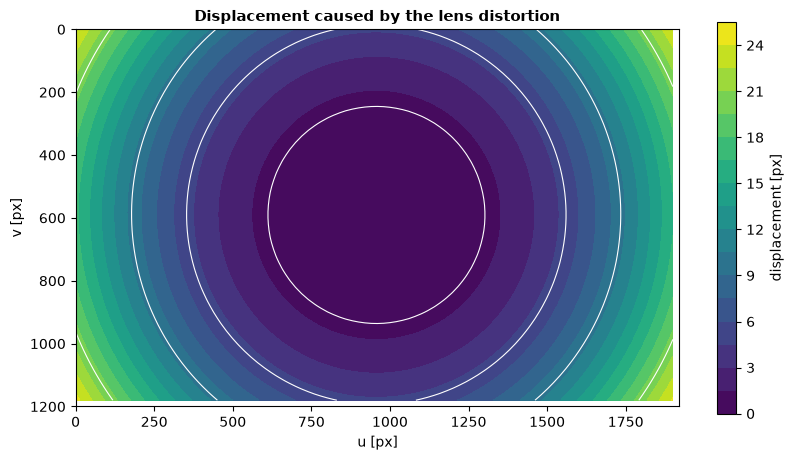

In [3]:
v, u = np.mgrid[0:camera.height:20, 0:camera.width:20]
normalized = np.column_stack([(u.ravel() - camera.cx) / camera.fx, (v.ravel() - camera.cy) / camera.fy])
distorted = camera.distort(normalized)
shift = np.hypot(camera.fx * (distorted[:, 0] - normalized[:, 0]), camera.fy * (distorted[:, 1] - normalized[:, 1]))
shift = shift.reshape(u.shape)

fig, ax = plt.subplots(figsize=(8.5, 4.6))
image = ax.contourf(u, v, shift, levels=20, cmap="viridis")
ax.contour(u, v, shift, levels=[1, 5, 10, 20, 40], colors="white", linewidths=0.8)
ax.set_xlim(0, camera.width); ax.set_ylim(camera.height, 0); ax.set_aspect("equal")
ax.set_xlabel("u [px]"); ax.set_ylabel("v [px]"); ax.grid(False)
ax.set_title("Displacement caused by the lens distortion")
fig.colorbar(image, ax=ax, label="displacement [px]")
fig.tight_layout()

radius = np.hypot(u - camera.cx, v - camera.cy)
print(f"displacement: {shift[radius < 200].max():.2f} px within 200 px of the center, "
      f"{shift[radius < 600].max():.1f} px within 600 px, {shift.max():.0f} px in the corners")

Near the center of the image the lens is practically ideal, a fifth of a pixel within 200 px of the axis. It is not further out: 5 px at 600 px from the center and 25 px in the corners. Since the target of SPEED+ is almost always within a few degrees of the optical axis, most keypoints are in the region where the distortion is small, but those of a target at 2 m fill the image and reach the edges. A pose computed with the ideal pinhole would be wrong by many pixels exactly in the cases where the target is closest, so the distortion is part of every projection from here on.

## The labels

Each image comes with the quaternion of the rotation from the camera frame to the body frame of Tango, `q_vbs2tango_true`, and the position of the body origin in the camera frame, `r_Vo2To_vbs_true`, in metres. In this version of the dataset the images taken in the laboratory are labeled too.

In [4]:
domains = {("synthetic", "train"): "synthetic, training", ("synthetic", "validation"): "synthetic, validation",
           ("lightbox", "test"): "lightbox", ("sunlamp", "test"): "sunlamp"}
labels = {key: dataset.labels(*key) for key in domains}

for key, name in domains.items():
    entries = labels[key]
    distance = np.array([entry.distance for entry in entries])
    norm = np.array([np.linalg.norm(entry.quaternion) for entry in entries])
    negative = np.mean([entry.quaternion[0] < 0 for entry in entries])
    print(f"{name:22s} {len(entries):6d} images; distance {distance.min():.2f} to {distance.max():.2f} m, "
          f"median {np.median(distance):.2f}; quaternion norm within {np.abs(norm - 1).max():.0e} of 1; "
          f"negative scalar part in {negative * 100:.0f} %")

synthetic, training     47966 images; distance 2.25 to 10.00 m, median 6.14; quaternion norm within 9e-07 of 1; negative scalar part in 50 %
synthetic, validation   11994 images; distance 2.25 to 10.00 m, median 6.15; quaternion norm within 8e-07 of 1; negative scalar part in 50 %
lightbox                 6740 images; distance 2.47 to 9.55 m, median 6.00; quaternion norm within 8e-13 of 1; negative scalar part in 30 %
sunlamp                  2791 images; distance 2.48 to 9.55 m, median 6.00; quaternion norm within 8e-13 of 1; negative scalar part in 31 %


The synthetic images cover distances from 2.25 to 10 m evenly, the laboratory images from 2.5 to 9.5 m. Every quaternion has unit norm. Half of the synthetic ones have a negative scalar part: the dataset does not fix the sign, which is legitimate since $\vect q$ and $-\vect q$ are the same rotation, but it means that two quaternions have to be compared through the angle between them, never component by component.

## Checking the convention

The convention stated in the chapter is $\vect p_c = R^{\mathsf T}\vect p_b + \vect t$, with $R$ the matrix of the labeled quaternion. If it were the other way around, $\vect p_c = R\,\vect p_b + \vect t$, the projected target would still look like a plausible satellite, only in the wrong orientation. The test below decides between the two on the images themselves.

It uses synthetic images with a black background, where the bright pixels are the satellite. For each image it projects the body of Tango with both conventions, takes the region it covers, and measures how well that region overlaps the bright pixels, as the ratio between their intersection and their union. The right convention must give the larger overlap, and by a clear margin.

40 images: overlap with the labeled convention 0.71 (median), with the transposed one 0.33; the labeled convention wins in 39 of 40


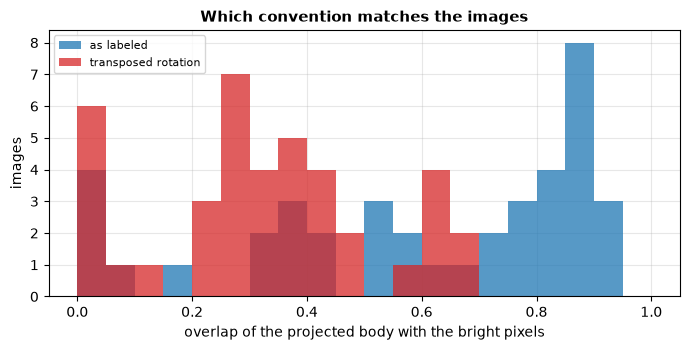

In [5]:
step = 4
grid_v, grid_u = np.mgrid[0:camera.height:step, 0:camera.width:step]
grid = np.column_stack([grid_u.ravel(), grid_v.ravel()])


def covered(pixels):
    hull = ConvexHull(pixels)
    return Polygon(pixels[hull.vertices]).contains_points(grid).reshape(grid_u.shape)


def overlap(a, b):
    return (a & b).sum() / max((a | b).sum(), 1)


rng = np.random.default_rng(0)
train = labels[("synthetic", "train")]
scores = {"as labeled": [], "transposed": []}
for index in rng.permutation(len(train)):
    label = train[index]
    image = dataset.image("synthetic", label.filename)[::step, ::step]
    if np.median(image) > 12 or (image > 60).mean() > 0.5 or (image > 30).sum() < 200:
        continue                    # Earth in the background, or satellite in shadow
    bright = image > 30
    for name, q in (("as labeled", label.quaternion), ("transposed", quaternion_conjugate(label.quaternion))):
        pixels, _ = project_pose(camera, q, label.translation, TANGO_KEYPOINTS[:8])
        scores[name].append(overlap(bright, covered(pixels)))
    if len(scores["as labeled"]) == 40:
        break

a, b = np.array(scores["as labeled"]), np.array(scores["transposed"])
print(f"{len(a)} images: overlap with the labeled convention {np.median(a):.2f} (median), "
      f"with the transposed one {np.median(b):.2f}; the labeled convention wins in {(a > b).sum()} of {len(a)}")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(a, bins=np.linspace(0, 1, 21), alpha=0.75, color=COL_A, label="as labeled")
ax.hist(b, bins=np.linspace(0, 1, 21), alpha=0.75, color=COL_B, label="transposed rotation")
ax.set_xlabel("overlap of the projected body with the bright pixels"); ax.set_ylabel("images")
ax.set_title("Which convention matches the images")
ax.legend(fontsize=8)
fig.tight_layout()

The convention of the chapter matches the images: its projection covers the bright pixels with a median overlap of 0.71, the transposed one with 0.33, and it is the better of the two in 39 images out of 40. The overlap does not reach 1 because the convex region spanned by the eight body points is only an approximation of the silhouette, which also contains the antennas and leaves out the shadowed faces; the comparison between the two conventions is what matters, and it is not close.

## The target as the camera sees it

With the convention settled, the labels alone tell how Tango appears in every image. The drawings below are not the images of the dataset: they are the edges of the body and the antennas projected with the labeled pose, for six images chosen across the range of distances.

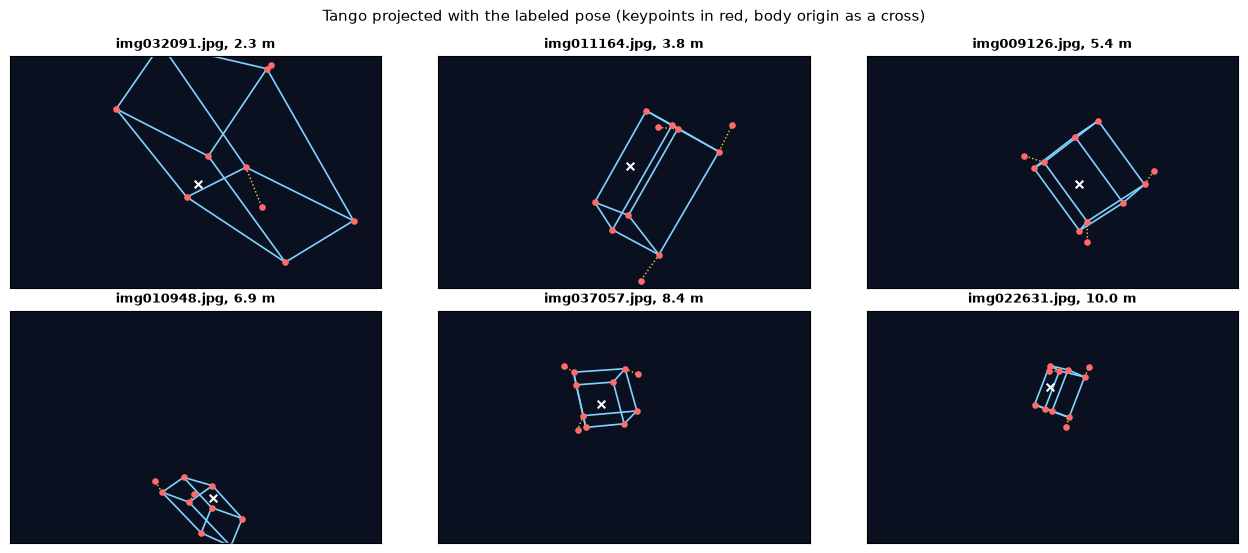

In [6]:
distance = np.array([label.distance for label in train])
order = np.argsort(distance)
picks = [train[order[int(f * (len(order) - 1))]] for f in (0.0, 0.2, 0.4, 0.6, 0.8, 1.0)]

fig, axes = plt.subplots(2, 3, figsize=(13, 5.6))
for ax, label in zip(axes.ravel(), picks):
    pixels, _ = project_pose(camera, label.quaternion, label.translation, TANGO_KEYPOINTS)
    origin, _ = project_pose(camera, label.quaternion, label.translation, np.zeros((1, 3)))
    ax.add_patch(plt.Rectangle((0, 0), camera.width, camera.height, color="#0b1020"))
    for i, j in TANGO_EDGES:
        ax.plot(pixels[[i, j], 0], pixels[[i, j], 1], color="#7fd3ff", lw=1.2)
    for k, base in ((8, 1), (9, 2), (10, 3)):
        ax.plot(pixels[[base, k], 0], pixels[[base, k], 1], color="#ffd23a", lw=1.0, ls=":")
    ax.scatter(pixels[:, 0], pixels[:, 1], s=14, color="#ff6b6b", zorder=5)
    ax.scatter(*origin[0], marker="x", color="white", s=30, zorder=6)
    ax.set_xlim(0, camera.width); ax.set_ylim(camera.height, 0); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(f"{label.filename}, {label.distance:.1f} m", fontsize=9)
fig.suptitle("Tango projected with the labeled pose (keypoints in red, body origin as a cross)", fontsize=11)
fig.tight_layout()

## The dataset from the point of view of pose estimation

What makes a pose easy or hard to recover is how large the target appears, how many keypoints are inside the image, and where in the image the target is. The statistics below are computed from the labels of the training set and of the two laboratory sets.

synthetic, training  apparent size: median 609 px (5th to 95th percentile 374 to 1430); all 11 keypoints inside: 83 %, at least 8: 98.5 %; target off the optical axis: median 2.6 deg, max 10.6 deg
lightbox             apparent size: median 619 px (5th to 95th percentile 394 to 1306); all 11 keypoints inside: 85 %, at least 8: 99.1 %; target off the optical axis: median 2.6 deg, max 9.6 deg
sunlamp              apparent size: median 624 px (5th to 95th percentile 389 to 1351); all 11 keypoints inside: 85 %, at least 8: 99.4 %; target off the optical axis: median 2.6 deg, max 9.0 deg


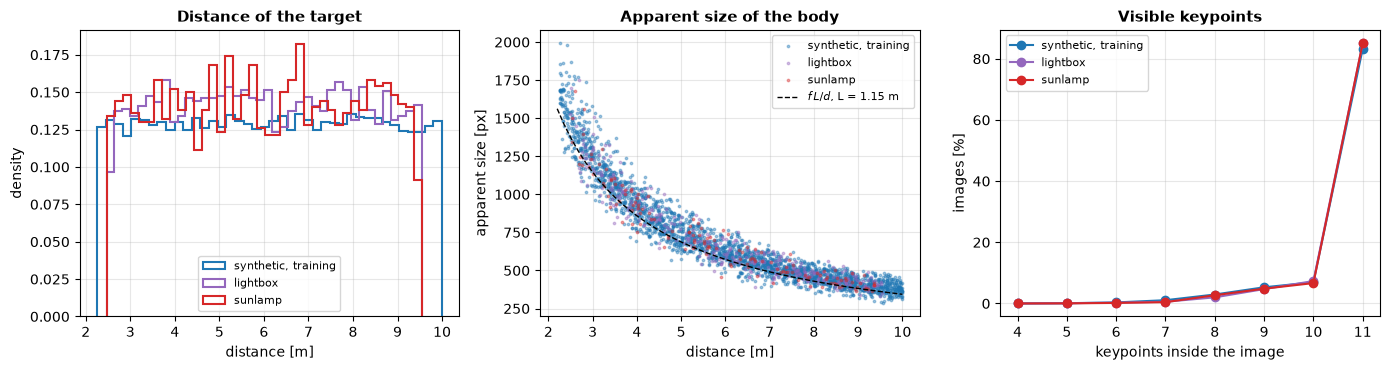

In [7]:
def describe(entries):
    size, inside, off_axis, dist = [], [], [], []
    for entry in entries:
        pixels, _ = project_pose(camera, entry.quaternion, entry.translation, TANGO_KEYPOINTS)
        body = pixels[:8]
        size.append(np.linalg.norm(body.max(axis=0) - body.min(axis=0)))
        inside.append(camera.in_image(pixels).sum())
        off_axis.append(np.degrees(np.arctan2(np.linalg.norm(entry.translation[:2]), entry.translation[2])))
        dist.append(entry.distance)
    return {k: np.array(v) for k, v in zip(("size", "inside", "off_axis", "distance"), (size, inside, off_axis, dist))}


stats = {name: describe(labels[key]) for key, name in domains.items() if key[1] != "validation"}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for (name, s), color in zip(stats.items(), (COL_A, COL_C, COL_B)):
    axes[0].hist(s["distance"], bins=40, density=True, histtype="step", lw=1.5, color=color, label=name)
    axes[1].scatter(s["distance"][::20], s["size"][::20], s=3, alpha=0.4, color=color, label=name)
    counts = np.bincount(s["inside"], minlength=12)[4:] / len(s["inside"])
    axes[2].plot(np.arange(4, 12), counts * 100, "o-", color=color, label=name)
d = np.linspace(2.2, 10, 50)
axes[1].plot(d, camera.fx * 1.15 / d, "k--", lw=1, label=r"$f\,L/d$, L = 1.15 m")
axes[0].set_xlabel("distance [m]"); axes[0].set_ylabel("density"); axes[0].set_title("Distance of the target")
axes[1].set_xlabel("distance [m]"); axes[1].set_ylabel("apparent size [px]"); axes[1].set_title("Apparent size of the body")
axes[2].set_xlabel("keypoints inside the image"); axes[2].set_ylabel("images [%]"); axes[2].set_title("Visible keypoints")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()

for name, s in stats.items():
    print(f"{name:20s} apparent size: median {np.median(s['size']):.0f} px (5th to 95th percentile "
          f"{np.percentile(s['size'], 5):.0f} to {np.percentile(s['size'], 95):.0f}); all 11 keypoints inside: "
          f"{(s['inside'] == 11).mean() * 100:.0f} %, at least 8: {(s['inside'] >= 8).mean() * 100:.1f} %; "
          f"target off the optical axis: median {np.median(s['off_axis']):.1f} deg, max {s['off_axis'].max():.1f} deg")

The three domains are alike in geometry, which is what makes them comparable: the laboratory images were taken to reproduce the distribution of the synthetic ones. The body appears about 600 px across at the median distance, between 370 and 1430 px over the whole range, and its size follows $f\,L/d$ with $L$ the diagonal of the body. All eleven keypoints are inside the image in 83 to 85 percent of the images and at least eight in 98 to 99 percent: the cases in which a keypoint falls outside are the close ones, where the target fills the image. The target is rarely far from the optical axis, 2.6 degrees on median and never more than 11.

The first number is the one that the next chapter turns into an accuracy. If a keypoint is located with an error of a few pixels on a target 600 px wide, the orientation is known to a fraction of a degree; at 10 m, with the target 400 px wide, the same pixel error weighs half as much again.

## Summary

`PinholeCamera`, `project_pose` and `SpeedPlus` reproduce the image formation of SPEED+, with the calibrated distortion of the lens, which reaches 25 px in the corners of the image. The convention of the poses was verified on the images, not taken from the documentation: the labeled quaternion is the rotation from the camera frame to the body frame, scalar part first, and a body point reaches the camera frame as $R^{\mathsf T}\vect p_b + \vect t$.

From the point of view of pose estimation the dataset presents a target between 2.25 and 10 m, a few hundred to over a thousand pixels across, with almost all of its keypoints visible. The next chapter inverts the forward model: given the pixels of the keypoints, it recovers the pose, and it measures how accurately a given pixel error allows it.